# Skyrun Customer Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile, warnings
from pathlib import Path
from google.colab import files
from IPython.display import display

In [ ]:
import pandas as pd

df = pd.read_csv('/content/Skyrun dataset.csv')

df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country
0,536365,2024-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt
1,536365,2024-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali
2,536365,2024-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali
3,536365,2024-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa
4,536365,2024-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda


In [ ]:
# Check the number of rows and columns
df.shape

(541909, 8)

In [ ]:
# Display column names
df.columns

Index(['InvoiceNo', 'InvoiceDate', 'CustomerID', 'StockCode', 'Description',
       'Quantity', 'UnitPrice', 'Country'],
      dtype='object')

In [ ]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   InvoiceDate  541909 non-null  object 
 2   CustomerID   406829 non-null  float64
 3   StockCode    541909 non-null  object 
 4   Description  541909 non-null  object 
 5   Quantity     541909 non-null  int64  
 6   UnitPrice    541909 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
# Statistical summary
df.describe()

,CustomerID,Quantity,UnitPrice
count,406829.000000,541909.000000,541909.000000
mean,15287.690570,50.534748,50.476354
std,1713.600303,28.849367,28.564775
min,12346.000000,1.000000,1.000000
25%,13953.000000,26.000000,25.750000
50%,15152.000000,51.000000,50.430000
75%,16791.000000,76.000000,75.180000
max,18287.000000,100.000000,100.000000


In [ ]:
# Check missing values
df.isnull().sum()

,0
InvoiceNo,0
InvoiceDate,0
CustomerID,135080
StockCode,0
Description,0
Quantity,0
UnitPrice,0
Country,0


In [ ]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

Cleaning and processing of data

In [ ]:
# Convert InvoiceDate into datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Remove rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Convert CustomerID into string
df['CustomerID'] = df['CustomerID'].astype(str)

# Remove duplicate records
df = df.drop_duplicates()

# Create TotalPrice column
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Check cleaned dataset
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,TotalPrice
0,536365,2024-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt,664.95
1,536365,2024-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali,1862.95
2,536365,2024-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali,4796.22
3,536365,2024-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa,370.95
4,536365,2024-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda,1941.50


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406829 non-null  object        
 1   InvoiceDate  406829 non-null  datetime64[ns]
 2   CustomerID   406829 non-null  object        
 3   StockCode    406829 non-null  object        
 4   Description  406829 non-null  object        
 5   Quantity     406829 non-null  int64         
 6   UnitPrice    406829 non-null  float64       
 7   Country      406829 non-null  object        
 8   TotalPrice   406829 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 31.0+ MB


In [ ]:
df.shape

(406829, 9)

In [ ]:
# business matrics calculation

# Total Revenue
total_revenue = df['TotalPrice'].sum()

# Total Customers
total_customers = df['CustomerID'].nunique()

# Total Orders
total_orders = df['InvoiceNo'].nunique()

# Total Products
total_products = df['StockCode'].nunique()

print("Total Revenue:", total_revenue)
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)
print("Total Products:", total_products)

Total Revenue: 1037435721.1100001
Total Customers: 4372
Total Orders: 22190
Total Products: 9000


EDA

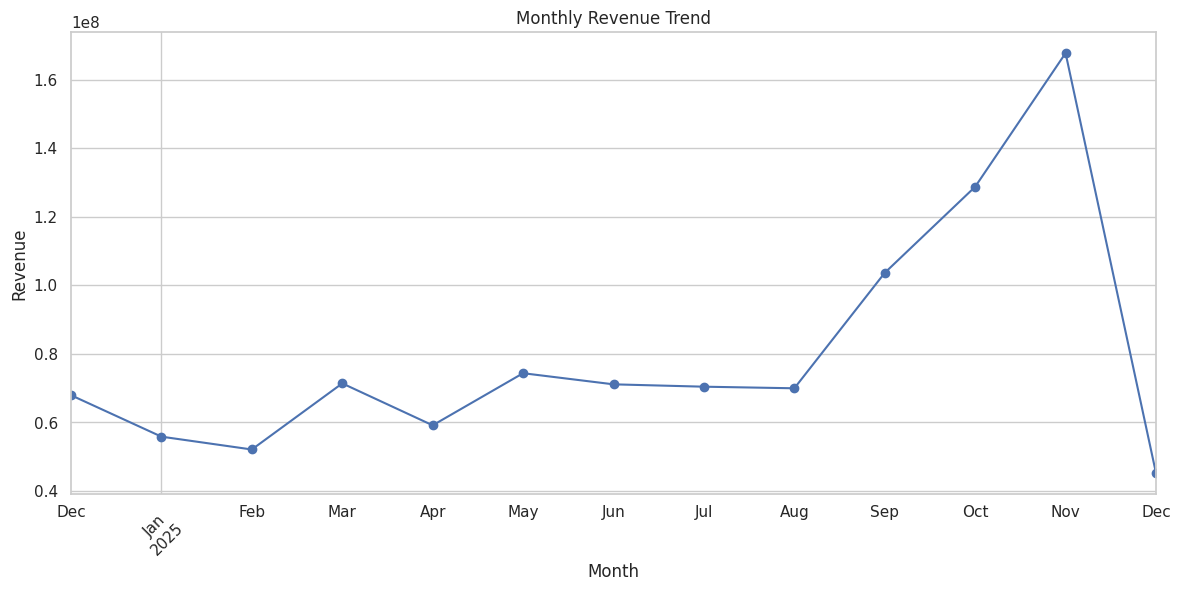

In [ ]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')


#monthy revenue
monthly_revenue = df.groupby('InvoiceMonth')['TotalPrice'].sum()

plt.figure(figsize=(14,6))
monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

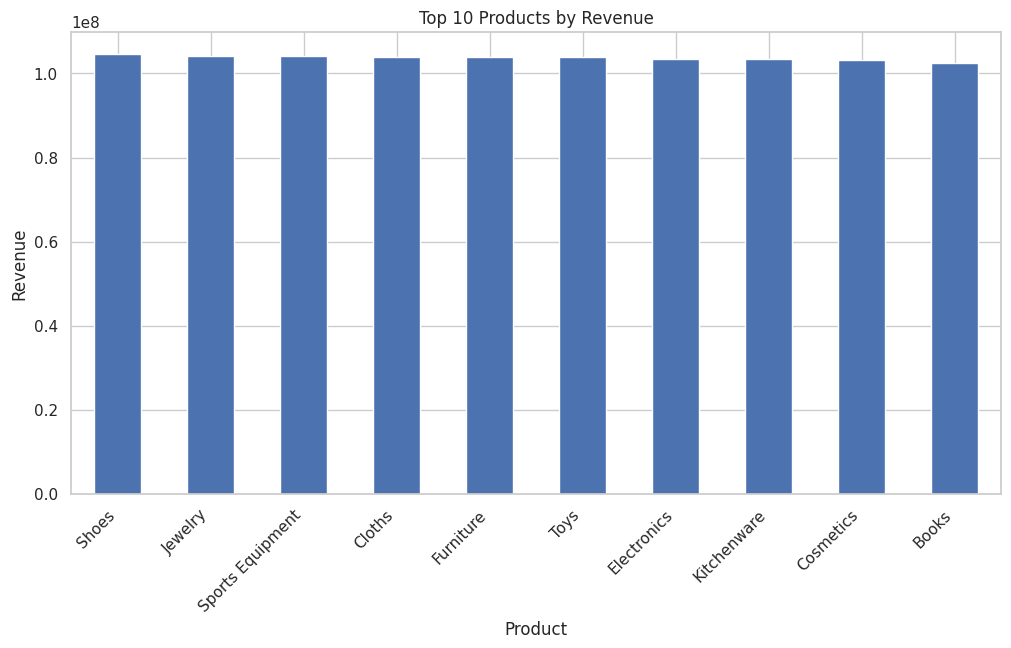

In [ ]:
#top products by revenue

top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
top_products.plot(kind='bar')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.xticks(rotation=45, ha='right')
plt.show()

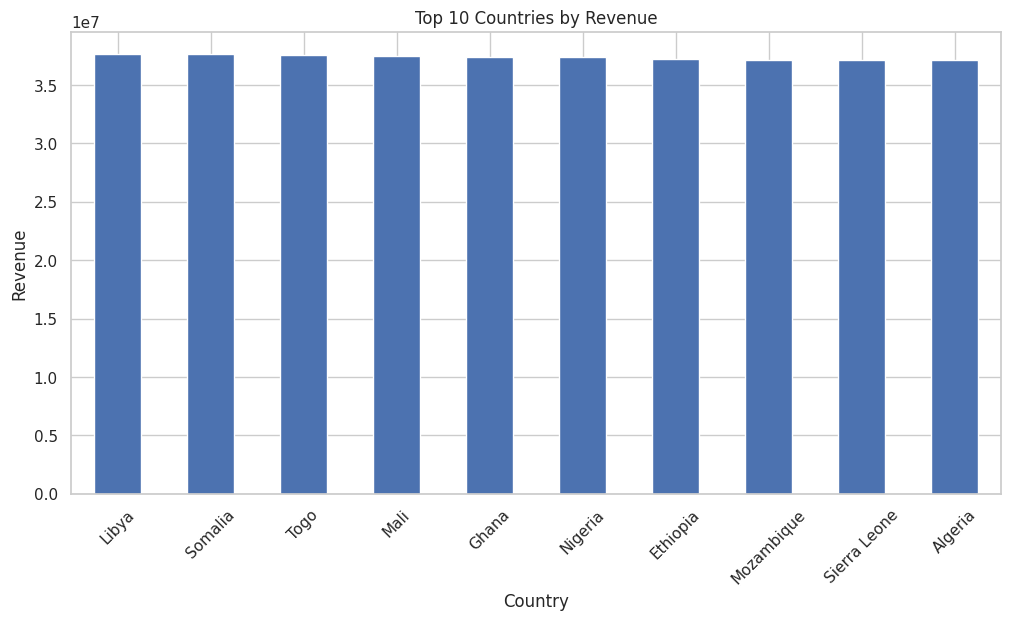

In [ ]:
#revenue by country
country_revenue = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
country_revenue.plot(kind='bar')

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Country')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

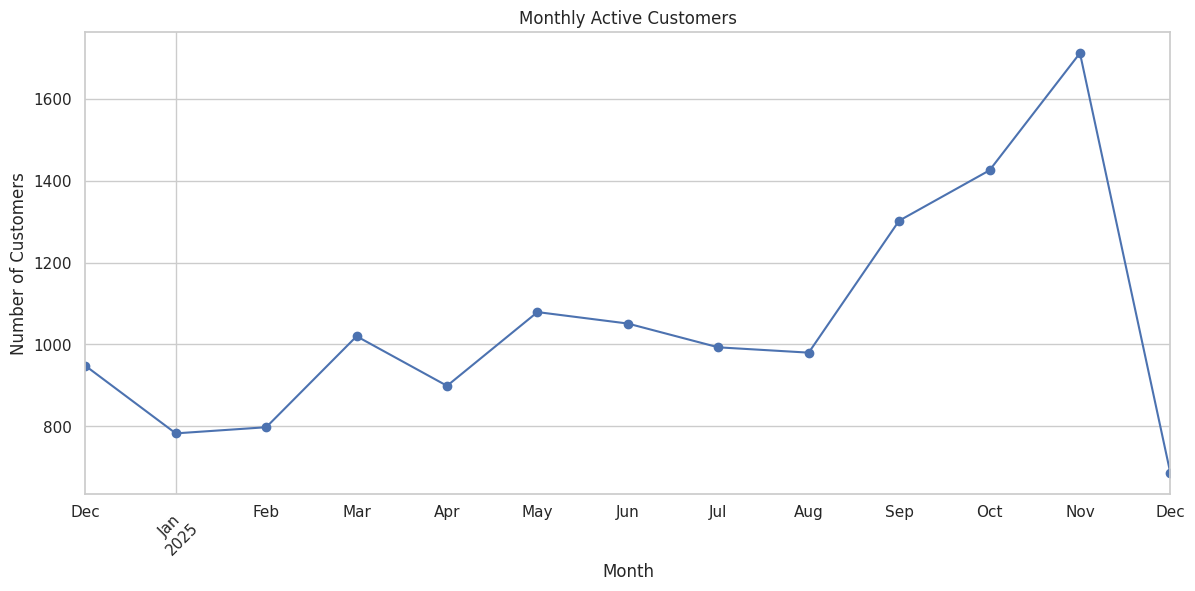

In [ ]:
#monthy active customers

monthly_customers = df.groupby('InvoiceMonth')['CustomerID'].nunique()

plt.figure(figsize=(14,6))
monthly_customers.plot(kind='line', marker='o')

plt.title('Monthly Active Customers')
plt.xlabel('Month')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

**Cohort Analysis**

In [ ]:
df['CohortMonth'] = df.groupby('CustomerID')['InvoiceDate'].transform('min').dt.to_period('M')

df[['CustomerID', 'InvoiceDate', 'CohortMonth']].head()

#Identify the first purchase month for each customer.

,CustomerID,InvoiceDate,CohortMonth
0,17850.0,2024-12-01 08:26:00,2024-12
1,17850.0,2024-12-01 08:26:00,2024-12
2,17850.0,2024-12-01 08:26:00,2024-12
3,17850.0,2024-12-01 08:26:00,2024-12
4,17850.0,2024-12-01 08:26:00,2024-12


In [ ]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

df[['InvoiceDate', 'InvoiceMonth']].head()

#Identify the invoice month.

,InvoiceDate,InvoiceMonth
0,2024-12-01 08:26:00,2024-12
1,2024-12-01 08:26:00,2024-12
2,2024-12-01 08:26:00,2024-12
3,2024-12-01 08:26:00,2024-12
4,2024-12-01 08:26:00,2024-12


In [ ]:
#calculate cohort index
df['CohortIndex'] = (
    (df['InvoiceMonth'].dt.year - df['CohortMonth'].dt.year) * 12 +
    (df['InvoiceMonth'].dt.month - df['CohortMonth'].dt.month) + 1
)

df[['CustomerID', 'CohortMonth', 'InvoiceMonth', 'CohortIndex']].head()

,CustomerID,CohortMonth,InvoiceMonth,CohortIndex
0,17850.0,2024-12,2024-12,1
1,17850.0,2024-12,2024-12,1
2,17850.0,2024-12,2024-12,1
3,17850.0,2024-12,2024-12,1
4,17850.0,2024-12,2024-12,1


In [ ]:
#Grouping customers by Cohort Month and Cohort Index.

cohort_data = df.groupby(
    ['CohortMonth', 'CohortIndex']
)['CustomerID'].nunique().reset_index()

cohort_data.head()

,CohortMonth,CohortIndex,CustomerID
0,2024-12,1,948
1,2024-12,2,362
2,2024-12,3,317
3,2024-12,4,367
4,2024-12,5,341


In [ ]:
#cohort pivot table
cohort_counts = cohort_data.pivot_table(
    index='CohortMonth',
    columns='CohortIndex',
    values='CustomerID'
)

cohort_counts

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,948.0,362.0,317.0,367.0,341.0,376.0,360.0,336.0,336.0,374.0,354.0,474.0,260.0
2025-01,421.0,101.0,119.0,102.0,138.0,126.0,110.0,108.0,131.0,146.0,155.0,63.0,NaN
2025-02,380.0,94.0,73.0,106.0,102.0,94.0,97.0,107.0,98.0,119.0,35.0,NaN,NaN
2025-03,440.0,84.0,112.0,96.0,102.0,78.0,116.0,105.0,127.0,39.0,NaN,NaN,NaN
2025-04,299.0,68.0,66.0,63.0,62.0,71.0,69.0,78.0,25.0,NaN,NaN,NaN,NaN
2025-05,279.0,66.0,48.0,48.0,60.0,68.0,74.0,29.0,NaN,NaN,NaN,NaN,NaN
2025-06,235.0,49.0,44.0,64.0,58.0,79.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,191.0,40.0,39.0,44.0,52.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,167.0,42.0,42.0,42.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Calculate customer retention

In [ ]:
cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(cohort_sizes, axis=0)

retention

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,1.0,0.381857,0.334388,0.387131,0.359705,0.396624,0.379747,0.354430,0.354430,0.394515,0.373418,0.500000,0.274262
2025-01,1.0,0.239905,0.282660,0.242280,0.327791,0.299287,0.261283,0.256532,0.311164,0.346793,0.368171,0.149644,NaN
2025-02,1.0,0.247368,0.192105,0.278947,0.268421,0.247368,0.255263,0.281579,0.257895,0.313158,0.092105,NaN,NaN
2025-03,1.0,0.190909,0.254545,0.218182,0.231818,0.177273,0.263636,0.238636,0.288636,0.088636,NaN,NaN,NaN
2025-04,1.0,0.227425,0.220736,0.210702,0.207358,0.237458,0.230769,0.260870,0.083612,NaN,NaN,NaN,NaN
2025-05,1.0,0.236559,0.172043,0.172043,0.215054,0.243728,0.265233,0.103943,NaN,NaN,NaN,NaN,NaN
2025-06,1.0,0.208511,0.187234,0.272340,0.246809,0.336170,0.102128,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,1.0,0.209424,0.204188,0.230366,0.272251,0.115183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,1.0,0.251497,0.251497,0.251497,0.137725,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


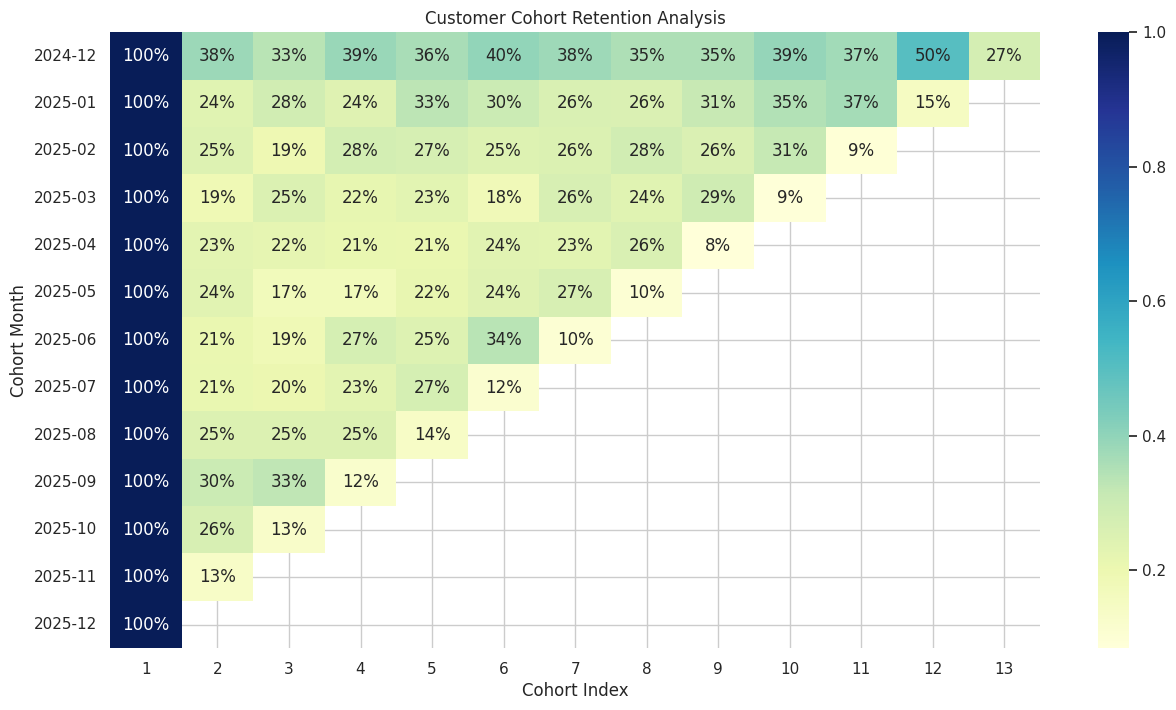

In [ ]:
#retention heat map
plt.figure(figsize=(15, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt='.0%',
    cmap='YlGnBu'
)

plt.title('Customer Cohort Retention Analysis')
plt.xlabel('Cohort Index')
plt.ylabel('Cohort Month')

plt.show()

RFM Analysis

In [ ]:
#Recency: How recently did the customer purchase?
#Frequency: How many different orders did the customer make?
#Monetary: How much money did the customer spend?

In [ ]:
#Set the reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

reference_date

Timestamp('2025-12-10 12:50:00')

In [ ]:
#Calculate RFM values
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['recency_days', 'frequency', 'monetary']
rfm.head()

,recency_days,frequency,monetary
CustomerID,,,
12346.0,326,2,5342.40
12347.0,2,7,431501.00
12348.0,75,4,82378.47
12349.0,19,1,176075.12
12350.0,310,1,48173.37


In [ ]:
rfm.describe()

,recency_days,frequency,monetary
count,4372.000000,4372.000000,4.372000e+03
mean,92.047118,5.075480,2.372909e+05
std,100.765435,9.338754,5.944603e+05
min,1.000000,1.000000,1.736000e+01
25%,17.000000,1.000000,4.350893e+04
50%,50.000000,3.000000,1.066925e+05
75%,143.000000,5.000000,2.599154e+05
max,374.000000,248.000000,2.038383e+07


In [ ]:
#RFM Scoring

# Recency score
rfm['R_Score'] = pd.qcut(
    rfm['recency_days'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
)

# Frequency score
rfm['F_Score'] = pd.qcut(
    rfm['frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Monetary score
rfm['M_Score'] = pd.qcut(
    rfm['monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head()

,recency_days,frequency,monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,2,5342.40,1,2,1
12347.0,2,7,431501.00,5,4,5
12348.0,75,4,82378.47,2,3,3
12349.0,19,1,176075.12,4,1,4
12350.0,310,1,48173.37,1,1,2


In [ ]:
#combine score
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

rfm.head()

,recency_days,frequency,monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,2,5342.40,1,2,1,121
12347.0,2,7,431501.00,5,4,5,545
12348.0,75,4,82378.47,2,3,3,233
12349.0,19,1,176075.12,4,1,4,414
12350.0,310,1,48173.37,1,1,2,112


customer segmentation

In [ ]:
def segment_customer(row):

    if row['RFM_Score'] == '555':
        return 'Champions'

    elif row['R_Score'] >= 4 and row['F_Score'] >= 4:
        return 'Loyal Customers'

    elif row['R_Score'] >= 4:
        return 'Recent Customers'

    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk'

    elif row['R_Score'] <= 2:
        return 'Lost Customers'

    else:
        return 'Potential Customers'


rfm['Segment'] = rfm.apply(segment_customer, axis=1)

rfm.head()

,recency_days,frequency,monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346.0,326,2,5342.40,1,2,1,121,Lost Customers
12347.0,2,7,431501.00,5,4,5,545,Loyal Customers
12348.0,75,4,82378.47,2,3,3,233,At Risk
12349.0,19,1,176075.12,4,1,4,414,Recent Customers
12350.0,310,1,48173.37,1,1,2,112,Lost Customers


In [ ]:
segment_summary = rfm.groupby('Segment').agg({
    'recency_days': 'mean',
    'frequency': 'mean',
    'monetary': 'mean'
})

segment_summary['Customer_Count'] = rfm.groupby('Segment').size()

segment_summary

,recency_days,frequency,monetary,Customer_Count
Segment,,,,
At Risk,153.399129,3.985486,1.478739e+05,689
Champions,4.745161,22.700000,1.141112e+06,310
Lost Customers,216.717925,1.201887,5.569192e+04,1060
Loyal Customers,14.869512,8.163415,3.513379e+05,820
Potential Customers,49.589245,3.699085,1.854566e+05,874
Recent Customers,16.174475,1.948304,1.172640e+05,619


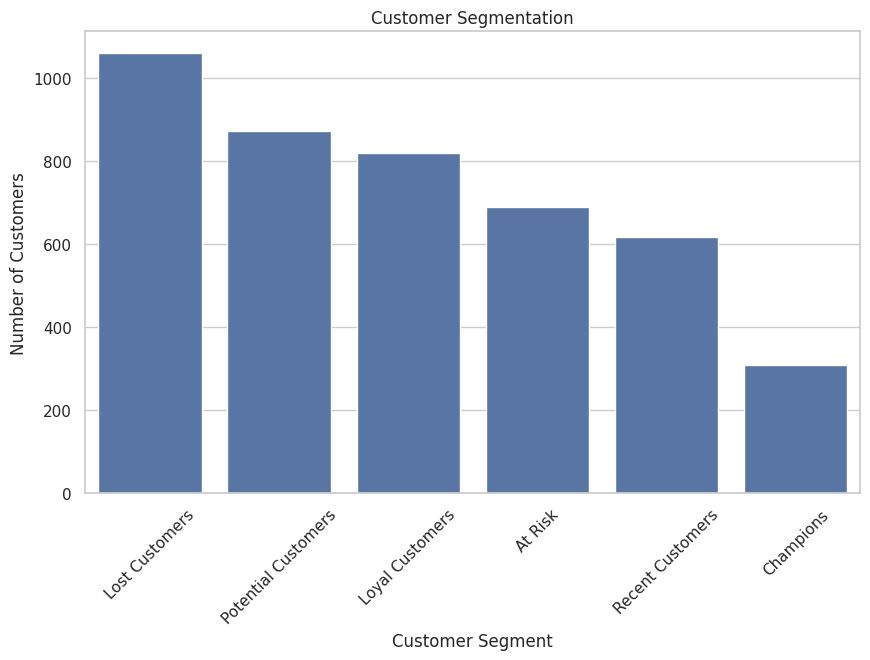

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=rfm,
    x='Segment',
    order=rfm['Segment'].value_counts().index
)

plt.title('Customer Segmentation')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

Business insights and reporting

In [ ]:
print("SKYRUN CUSTOMER ANALYSIS")
print("------------------------")

print("Total Revenue:", round(total_revenue, 2))
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)

print("\nCustomer Segmentation:")
print(rfm['Segment'].value_counts())

print("\nTop Revenue Months:")
print(monthly_revenue.sort_values(ascending=False).head(5))

print("\nRFM Segment Summary:")
print(segment_summary)

SKYRUN CUSTOMER ANALYSIS
------------------------
Total Revenue: 1037435721.11
Total Customers: 4372
Total Orders: 22190

Customer Segmentation:
Segment
Lost Customers         1060
Potential Customers     874
Loyal Customers         820
At Risk                 689
Recent Customers        619
Champions               310
Name: count, dtype: int64

Top Revenue Months:
InvoiceMonth
2025-11    1.677331e+08
2025-10    1.287425e+08
2025-09    1.036281e+08
2025-05    7.434151e+07
2025-03    7.137210e+07
Freq: M, Name: TotalPrice, dtype: float64

RFM Segment Summary:
                     recency_days  frequency      monetary  Customer_Count
Segment                                                                   
At Risk                153.399129   3.985486  1.478739e+05             689
Champions                4.745161  22.700000  1.141112e+06             310
Lost Customers         216.717925   1.201887  5.569192e+04            1060
Loyal Customers         14.869512   8.163415  3.513379e+05  

In [ ]:
#export

import os

os.makedirs('outputs', exist_ok=True)

# Export cleaned dataset
df.to_csv('outputs/cleaned_dataset.csv', index=False)

# Export cohort analysis
cohort_counts.to_csv('outputs/cohort_counts.csv')

retention.to_csv('outputs/cohort_retention.csv')

# Export RFM analysis
rfm.to_csv('outputs/customer_rfm_analysis.csv')

# Export summaries
segment_summary.to_csv('outputs/rfm_segment_summary.csv')

In [ ]:
import shutil
from google.colab import files

shutil.make_archive('Skyrun_Analysis_Outputs', 'zip', 'outputs')

files.download('Skyrun_Analysis_Outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
##reporting

In [ ]:
#report
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 7.0 MB/s  0:00:00
